In [52]:
# Load libraries
import pandas as pd
import numpy as np

# Visualisation libraries
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline


from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans



## Exploring the data

First we need to clean up the data for analysis and calculations later

In [53]:
# Load the dataset and use the country column as index.
df = pd.read_csv('iris.csv')

# Separate features and target
X = df.drop(columns=["Species"])
y = df["Species"]

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.100000,3.500000,1.400000,0.200000,Iris-setosa
1,2,4.900000,3.000000,1.400000,0.200000,Iris-setosa
2,3,4.700000,3.200000,1.300000,0.200000,Iris-setosa
3,4,4.600000,3.100000,1.500000,0.200000,Iris-setosa
4,5,5.000000,3.600000,1.400000,0.200000,Iris-setosa


In [54]:
# Printing the shape of the dataset
print('Number of flowers: {} Number of features: {}'.format(df.shape[0], df.shape[1]))

Number of flowers: 150 Number of features: 6


Identify any missing values and see which features are affected

In [55]:
# Count missing values
missing = df.isnull().sum()
relevant_missing = pd.DataFrame(missing, columns=["missing"])
relevant_missing

,missing
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


### 3. Explore the features and statistical properties of the dataset

In [56]:
# To set the decimal precision:
pd.set_option('display.float_format', lambda x: '%2f' % x)

# The describe() function gives us insight into the statistical properties of the columns
stats = df.describe()
selected_stats = stats.loc[["mean","std","min","max"]].transpose() # select relevant colums
selected_stats


,mean,std,min,max
Id,75.500000,43.445368,1.000000,150.000000
SepalLengthCm,5.843333,0.828066,4.300000,7.900000
SepalWidthCm,3.054000,0.433594,2.000000,4.400000
PetalLengthCm,3.758667,1.764420,1.000000,6.900000
PetalWidthCm,1.198667,0.763161,0.100000,2.500000


## Correlation analysis
### 4. Create a plot of the data using all features to show the positive and negative correlations between them.

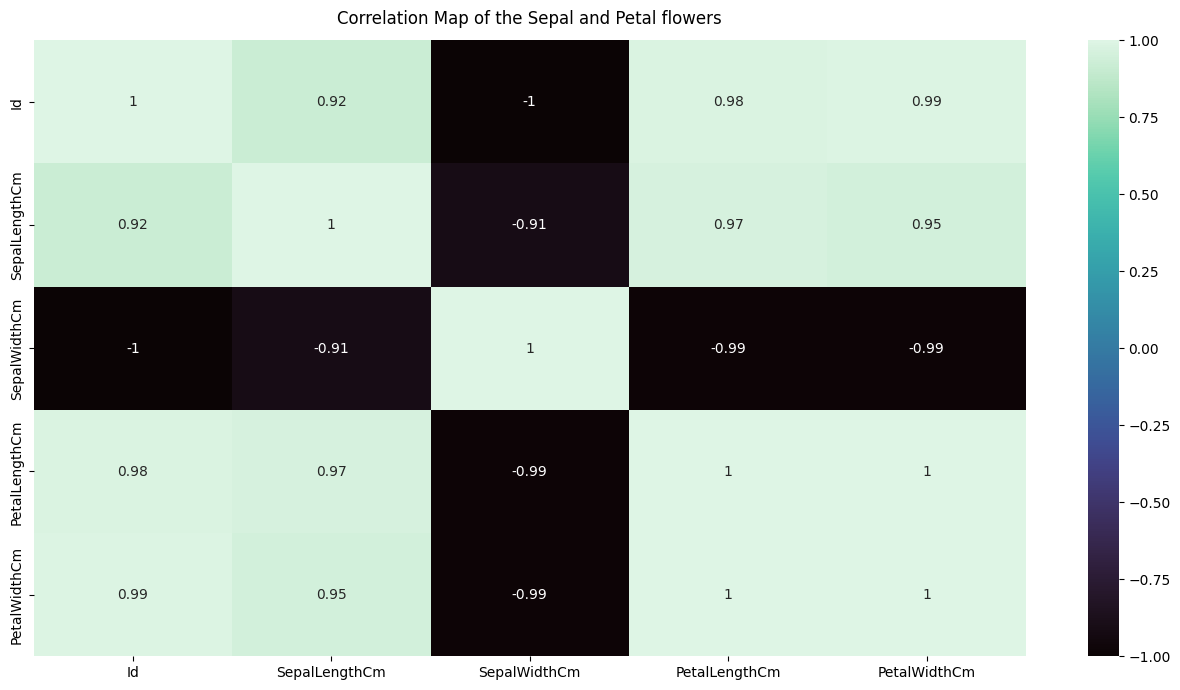

In [57]:
# Create a correlation map of features to explore the relationship between features
# Hint: Explore seaborn heatmap
species = df
corr_df = df.drop(["Species"], axis=1).corr()
labels = corr_df.columns

correlations = corr_df.corr()
plt.figure(figsize=(16, 8))
sns.heatmap(corr_df.corr(), vmin = -1, annot = True, cmap = 'mako')
plt.title('Correlation Map of the Sepal and Petal flowers', fontdict={'fontsize':12}, pad=12);

### 5. Scale the data (normalisation or standardisation), then apply PCA to it. Use n_components = 3.

In [58]:
# Normalize the data using MinMaxScaler
# Name the normalized dataframe "df_scaled"
# Standardize
# Select features
X = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]

# Target labels
y = df['Species']

# Standardise the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA (3 components)
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

#### Apply Principal Component Analysis use n_components = 3

##### Unstandardized data

In [59]:
# Run again if it does not converge the first time
np.set_printoptions(precision=4)

X = df.drop(columns=['Species'])

pca = PCA(n_components=3)

# Transform data
X_trans = pca.fit_transform(X)
df_pca = pd.DataFrame(X_trans)
df_pca.head()

,0,1,2
0,-74.547527,0.441426,0.164821
1,-73.549143,0.309342,-0.327344
2,-72.557120,0.084528,-0.244928
3,-71.551791,0.160353,-0.429890
4,-70.552763,0.227636,0.216170


#### Standardized data

We standardise the data so that some features do not swamp others.

In [60]:
# Standardising the data
pca = PCA(n_components=3)
X_trans = pca.fit_transform(X)

# Cell 9
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

pca_std = PCA(n_components=3)
X_std_trans = pca_std.fit_transform(X_std)

### 6. Plot a biplot with the transformed data.

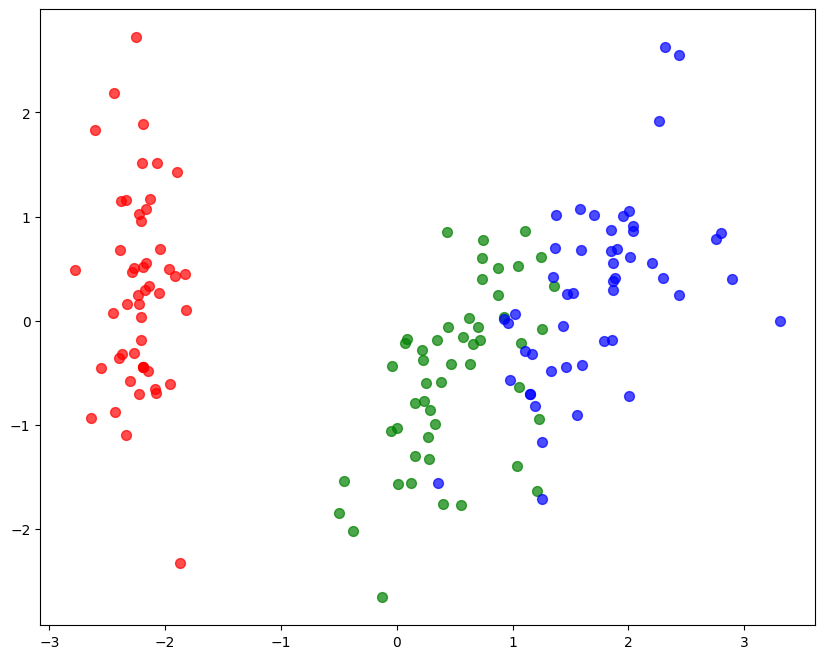

In [61]:
# Create biplot function
# Ensure species is a 1D NumPy array
species = df["Species"].to_numpy().ravel()

plt.figure(figsize=(10,8))

colours = {
    "Iris-setosa": "red",
    "Iris-versicolor": "green",
    "Iris-virginica": "blue"
}

for sp, colour in colours.items():

    mask = (species == sp)

    plt.scatter(
        X_pca[mask][:,0],
        X_pca[mask][:,1],
        color=colour,
        label=sp,
        s=50,
        alpha=0.7
    )


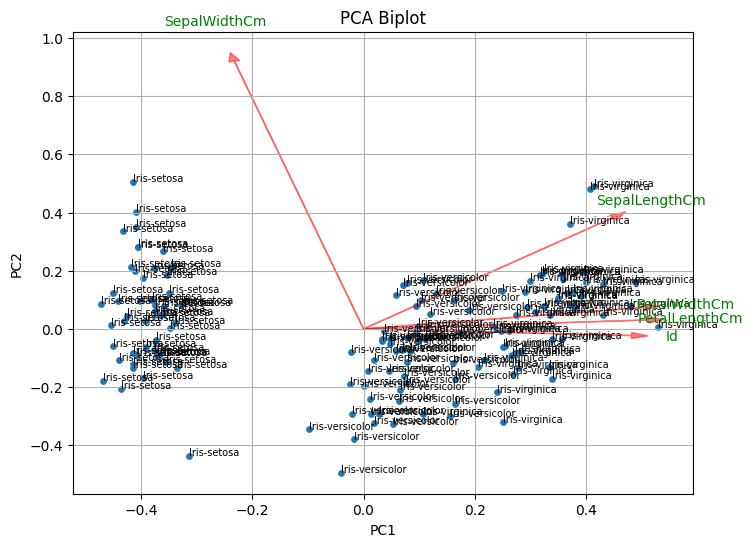

In [62]:
# Plot biplot
biplot(X_std_trans[:,0:2],np.transpose(pca_std.components_[0:2, :]),list(labels),list(species))
plt.show()

### 7. Cluster the data using hierarchical and k-means clustering. Did the clustering techniques identify the three species?

In [63]:
# Prepare data for K-means clustering, note that we do not supply y in an unsupervised learning environment
# Create K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model
kmeans.fit(X_pca)

# Cluster labels
clusters = kmeans.labels_

# Add clusters to the dataframe
df['Cluster'] = clusters

# Display first few rows
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,1,5.100000,3.500000,1.400000,0.200000,Iris-setosa,0
1,2,4.900000,3.000000,1.400000,0.200000,Iris-setosa,0
2,3,4.700000,3.200000,1.300000,0.200000,Iris-setosa,0
3,4,4.600000,3.100000,1.500000,0.200000,Iris-setosa,0
4,5,5.000000,3.600000,1.400000,0.200000,Iris-setosa,0


#### Perform hierachical clustering

In [64]:
# Create the linkage matrix using Ward's method
Z = linkage(X_pca, method='ward')

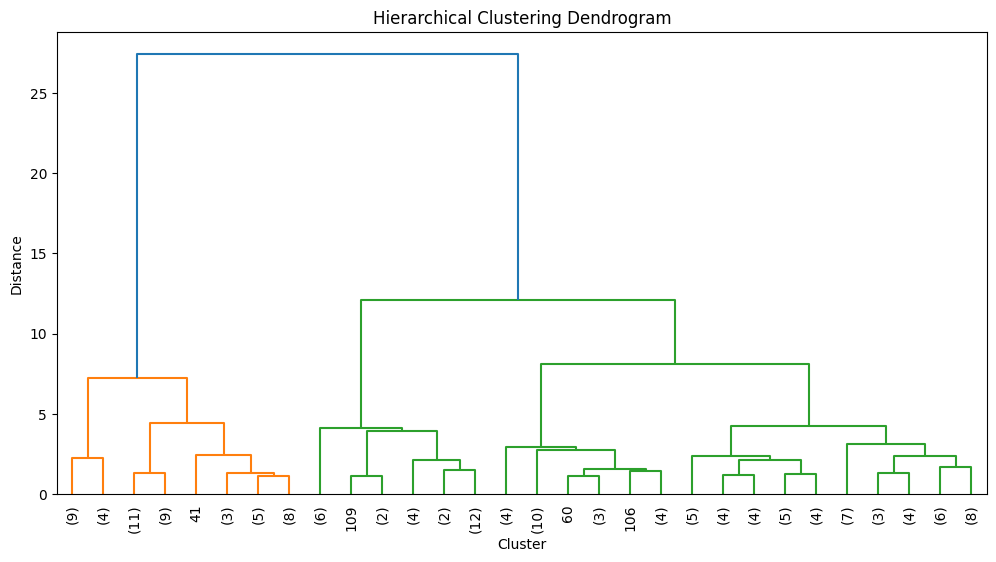

In [65]:
plt.figure(figsize=(12,6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.show()

Did the clustering techniques identify the three species

Yes the clustring techniques did identify the three species. Both K-Means and Hierarchical Clustering were applied to the Iris dataset after reducing the dimensionality using PCA. The goal was to group the observations into three clusters, corresponding to the three Iris species: Setosa, Versicolor, and Virginica.

Iris Setosa was identified very accurately by both clustering techniques because it is clearly separated from the other two species based on its flower measurements.
Iris Versicolor and Iris Virginica were not separated as clearly. These two species have similar petal and sepal measurements, causing some observations to be assigned to the wrong cluster.
As a result, both clustering methods produced three clusters that closely resembled the three species, but there was some overlap between Versicolor and Virginica.

The program uses the  elbow method for choosing a value for K. The elbow method is commonly used strategy in which the algorithm is run multiple times with increasing values of K. This is then plotted against the sum of squared distances of samples to their closest cluster centre (called inertia). The value of K choose os identified from the resulting plot where there is an elbow in the graph

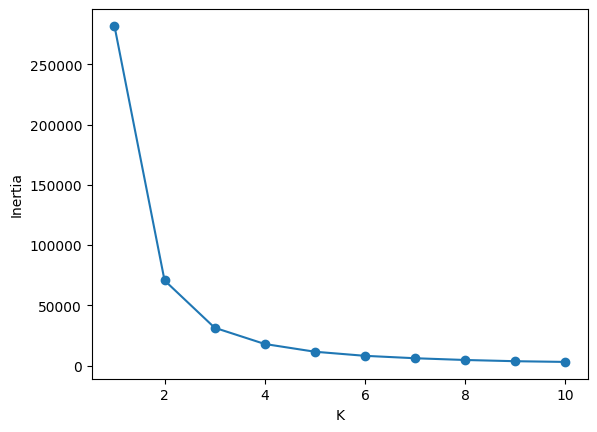

In [66]:
def eval_kmeans(x, k, r):
    """
    Evaluates the KMeans clustering for a given number of clusters (k) and random seed (r), returning
     the inertia (sum of squared distances of samples to their closest cluster centre)
    Args:
        x (str): Data to be clustered
        k (int): Number of clusters
        r (int): Random state for reproducibility.

    Returns:
    - inertia: Sum of squared distances within clusters
    """
    kmeans = KMeans(n_clusters=k, random_state=r)
    kmeans.fit(x)
    return kmeans.inertia_

def elbow_kmeans(x, max_k=10, r=123):
    """
    Plots the inertia (within-cluster variance) against the number of clusters to help determine the
    optimal number of clusters (the elbow point).

    Args:
        x (str): Data to be clustered
        max_k (int): Maximum number of clusters to evaluate (default is 10)
        r (int): Random state for reproducibility
    """
    within_cluster_vars = [eval_kmeans(x, k, r) for k in range(1, max_k+1)]
    plt.plot(range(1, 11), within_cluster_vars,marker='o')
    plt.xlabel('K')
    plt.ylabel('Inertia')
    plt.show()

elbow_kmeans(X)


The elbow runs from K=3, to K=5. In cases like this, it is not always clear which value within the elbow is the most optimal, so we can investigate likely candidates further using the silhoutte score.

### Fit a K-Means Model and Visualis the Outcome

Let's illustrate the differences with a scatter plot. Note how the silhouette score increases considerably between K=4 and K=5, but not between K=5 and K=6

In [67]:
def scatter_Kmeans(x, k, r=123):
    """
    Perform K-Means clustering and plot the clusters.

    Parameters:
        x : array-like
            Data to cluster (2D for plotting).
        k : int
            Number of clusters.
        r : int
            Random seed.
    """

    # Fit K-Means
    kmeans = KMeans(n_clusters=k,
                    init='k-means++',
                    random_state=r,
                    n_init=10)

    y_pred = kmeans.fit_predict(x)

    # Calculate silhouette score
    score = silhouette_score(x, y_pred)

    # Plot clusters
    plt.figure(figsize=(7,5))

    colours = ['red', 'blue', 'green', 'cyan', 'magenta', 'yellow']

    for c in range(k):
        plt.scatter(
            x[y_pred == c, 0],
            x[y_pred == c, 1],
            color=colours[c % len(colours)],
            label=f'Cluster {c+1}'
        )

        # Plot centroid
        plt.scatter(
            kmeans.cluster_centers_[c, 0],
            kmeans.cluster_centers_[c, 1],
            marker='X',
            s=200,
            color='black'
        )

    plt.title(f'K-Means Clustering (k={k})\nSilhouette Score = {score:.2f}')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.legend()
    plt.show()

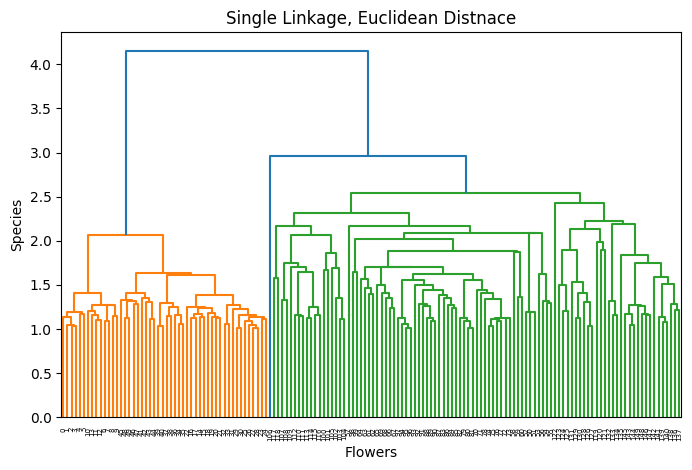

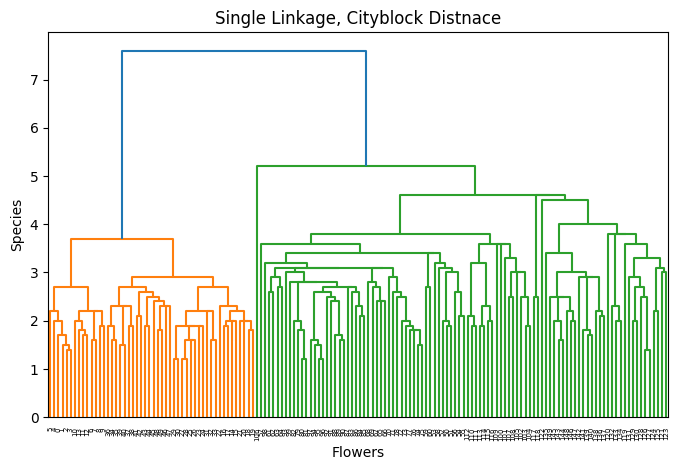

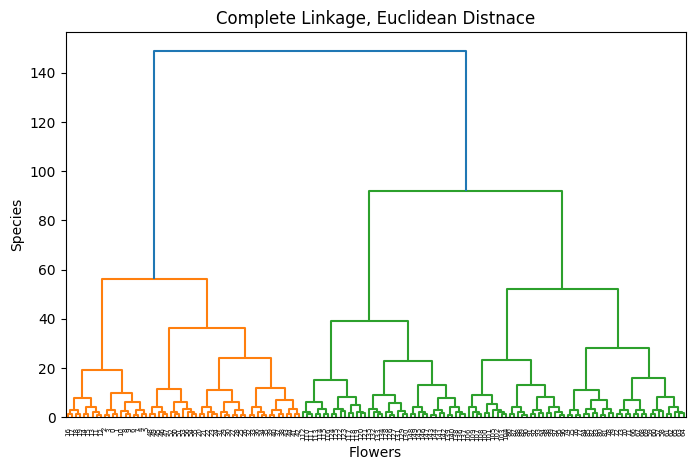

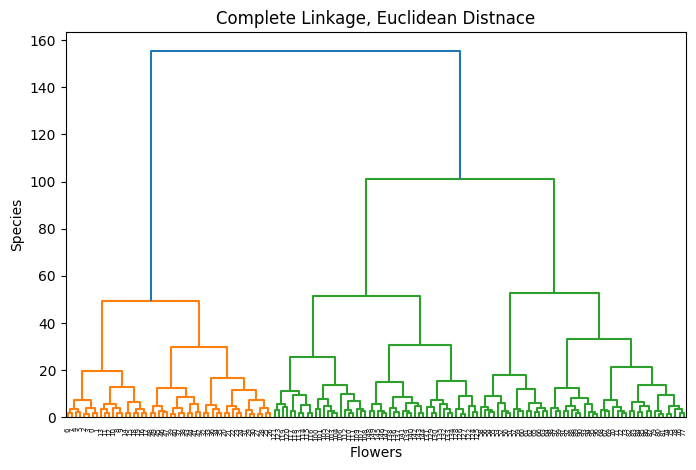

In [68]:
# Define a function to plot a dendrogram for a given linkage method and distance metrics
def plot_dendrogram(X, method, metric, title):
    """
    Plots a hierarchical clustering dendrogram for the given dataset.

    This function performs hierarchical clustering using the specified
    linkage method and distance metric, then displays the resulting
    dendrogram to visualize how observations are grouped into clusters.

    Parameters
    ----------
    X : array-like of shape (n_samples, n_features)
        The input dataset containing the observations to be clustered.

    method : str
        The linkage criterion used to compute the hierarchical clustering.

    metric : str
        The distance metric used to calculate pairwise distances between
        observations. Common options include:
        - 'euclidean'
        - 'cityblock' (Manhattan)


    title : str
        The title displayed on the dendrogram.

    Returns
    -------
    None
        Displays the dendrogram plot without returning a value.
    """
    plt.figure(figsize=(8,5))
    Z = linkage(X, method=method, metric=metric)
    dendrogram(Z)
    plt.title(title)
    plt.xlabel('Flowers')
    plt.ylabel('Species')
    plt.show()

# Plot the four dendrograms:
# Single linkage with Euclidean distance
plot_dendrogram(X, method = 'single', metric = 'euclidean', title = 'Single Linkage, Euclidean Distnace')

# Single linkage with Cityblock (Manhattan) distance
plot_dendrogram(X, method = 'single', metric = 'cityblock', title = 'Single Linkage, Cityblock Distnace')

# Complete Linkage with Euclidean distance
plot_dendrogram(X, method = 'complete', metric = 'euclidean', title = 'Complete Linkage, Euclidean Distnace')

# Complete linkage with Cityblock (Manhattan) distance
plot_dendrogram(X, method = 'complete', metric = 'cityblock', title = 'Complete Linkage, Euclidean Distnace')


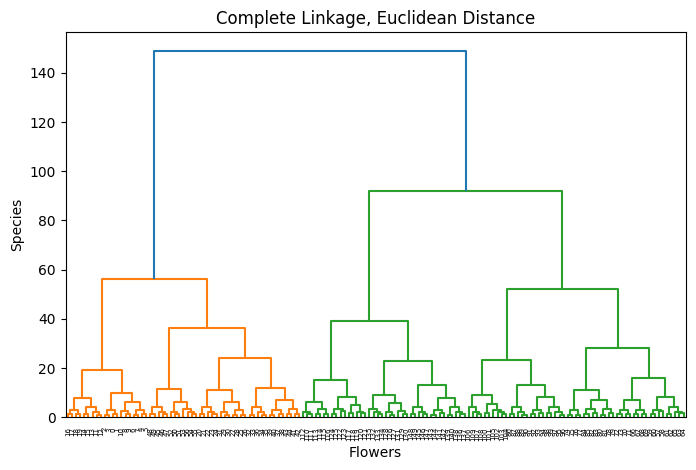

silhouette score:  0.573089
The clusters are well-defined, showing a high degree of separation.


In [69]:
# Plot the chosen dendrogram (Complete Linkage with Euclidean Distance)
plt.figure(figsize=(8, 5))
Z = linkage(X, method='complete', metric='euclidean')
dendrogram(Z)
plt.title('Complete Linkage, Euclidean Distance')
plt.xlabel('Flowers')
plt.ylabel('Species')
plt.show()

# Perform Agglomerative Hierarchical Clustering
# Assuming we select 3 clusters based on the dendrogram
agg_cluster = AgglomerativeClustering(n_clusters=3, linkage='complete', metric='euclidean')
labels = agg_cluster.fit_predict(X)

# calculate Silhoutte Score to evaluate clustering
silhouette_avg = silhouette_score(X, labels)
print(f"silhouette score: {silhouette_avg: 3f}")

# Comment on clustering confidence based on Silhouette Score
if silhouette_avg > 0.5:
    print("The clusters are well-defined, showing a high degree of separation.")
elif 0.2 < silhouette_avg <= 0.5:
    print("The clustering solution is acceptable but shows some overlap between clusters.")
else:
    print("The clusters are poorly defined, and the clustering solutions might need improvement")


### 8. After applying the PCA, recreate the correlation plot with the transformed data. Compare it to the original, nothing any reduction in redundancies.

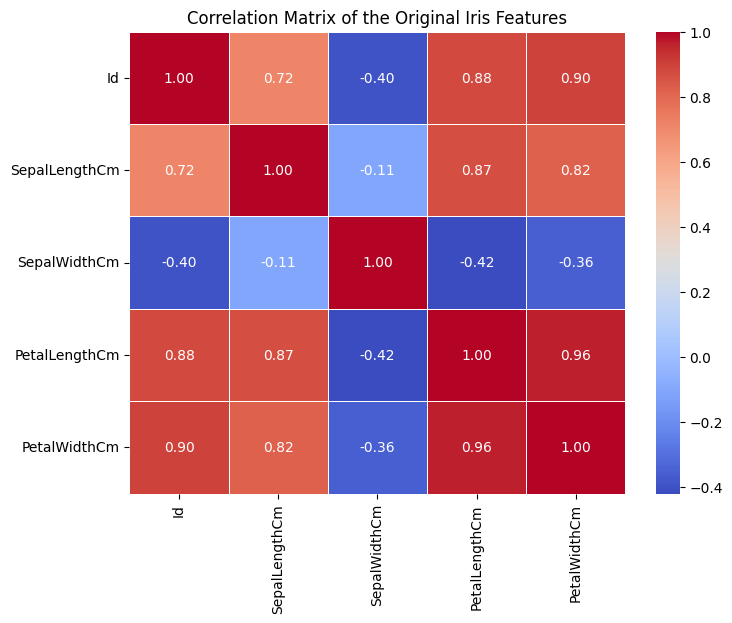

In [70]:
plt.figure(figsize=(8,6))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt='.2f'
)

plt.title('Correlation Matrix of the Original Iris Features')
plt.show()

In [71]:
# Create a DataFrame from the PCA transformed data
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2', 'PC3']
)

# Display the first few rows
pca_df.head()

,PC1,PC2,PC3
0,-2.264542,0.505704,0.121943
1,-2.086426,-0.655405,0.227251
2,-2.367950,-0.318477,-0.051480
3,-2.304197,-0.575368,-0.098860
4,-2.388777,0.674767,-0.021428


Correlation matrix of the transformed data

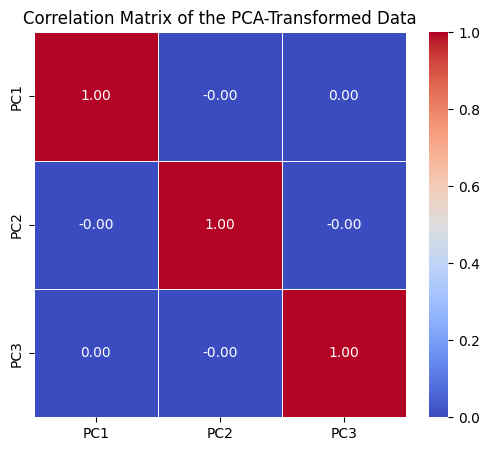

In [72]:
plt.figure(figsize=(6,5))

sns.heatmap(
    pca_df.corr(),
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt='.2f'
)

plt.title('Correlation Matrix of the PCA-Transformed Data')
plt.show()

Compare the transformed to the original correlations maps

In [73]:
print("Original Feature Correlation Matrix")
print(X.corr())

print("\n")

print("PCA Correlation Matrix")
print(pca_df.corr())

Original Feature Correlation Matrix
                     Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  \
Id             1.000000       0.716676     -0.397729       0.882747   
SepalLengthCm  0.716676       1.000000     -0.109369       0.871754   
SepalWidthCm  -0.397729      -0.109369      1.000000      -0.420516   
PetalLengthCm  0.882747       0.871754     -0.420516       1.000000   
PetalWidthCm   0.899759       0.817954     -0.356544       0.962757   

               PetalWidthCm  
Id                 0.899759  
SepalLengthCm      0.817954  
SepalWidthCm      -0.356544  
PetalLengthCm      0.962757  
PetalWidthCm       1.000000  


PCA Correlation Matrix
          PC1       PC2       PC3
PC1  1.000000 -0.000000  0.000000
PC2 -0.000000  1.000000 -0.000000
PC3  0.000000 -0.000000  1.000000
